MODULE 1: DATA LOADING & EXPLORATION

--- 1. Raw Dataset Preview (df.head()) ---
   total_bill   tip     sex smoker  day    time  size
0       16.99  1.01  Female     No  Sun  Dinner     2
1       10.34  1.66    Male     No  Sun  Dinner     3
2       21.01  3.50    Male     No  Sun  Dinner     3
3       23.68  3.31    Male     No  Sun  Dinner     2
4       24.59  3.61  Female     No  Sun  Dinner     4

--- 2. Dataset Structure & Data Types (df.info()) ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   total_bill  244 non-null    float64
 1   tip         244 non-null    float64
 2   sex         244 non-null    object 
 3   smoker      244 non-null    object 
 4   day         244 non-null    object 
 5   time        244 non-null    object 
 6   size        244 non-null    int64  
dtypes: float64(2), int64(1), object(4)
memory usage: 9.6+ KB

--- 

TypeError: boxplot() got an unexpected keyword argument 'legend'

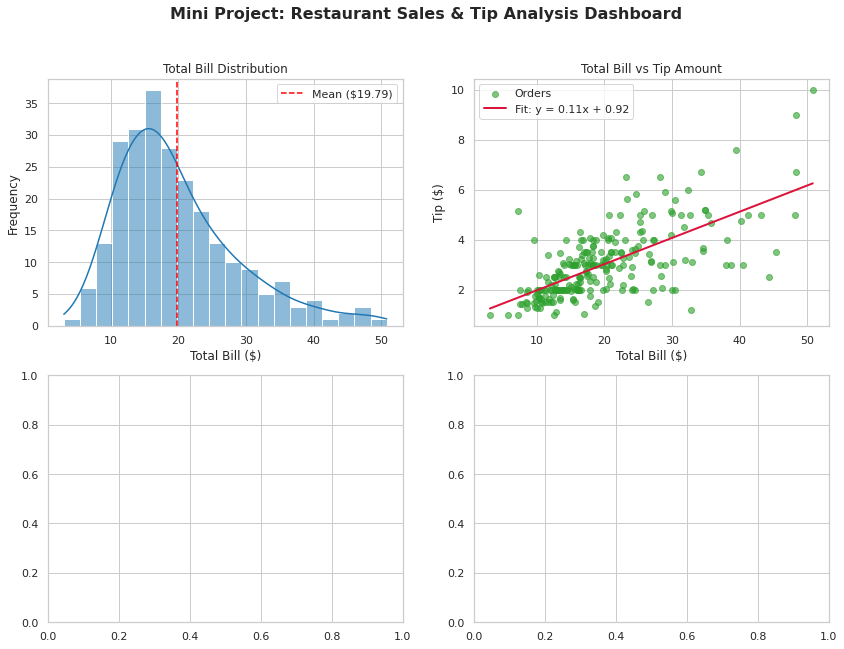

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Set overall plot aesthetics
sns.set_theme(style="whitegrid")
plt.rcParams["font.sans-serif"] = "DejaVu Sans"

# ==============================================================================
# MODULE 1: DATA LOADING & EXPLORATION (Pandas)
# ==============================================================================
print("=" * 60)
print("MODULE 1: DATA LOADING & EXPLORATION")
print("=" * 60)

# Load restaurant tips dataset (includes offline fallback for lab environments)
try:
    df = sns.load_dataset("tips")
except Exception:
    url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/tips.csv"
    df = pd.read_csv(url)

print("\n--- 1. Raw Dataset Preview (df.head()) ---")
print(df.head())

print("\n--- 2. Dataset Structure & Data Types (df.info()) ---")
df.info()

print("\n--- 3. Numerical Summary Statistics (df.describe()) ---")
print(df.describe())

# ==============================================================================
# MODULE 2: DATA CLEANING & PREPROCESSING (Pandas)
# ==============================================================================
print("\n" + "=" * 60)
print("MODULE 2: DATA CLEANING & PREPROCESSING")
print("=" * 60)

# Detect missing/null values
missing_count = df.isnull().sum()
print("Missing Values per Column:\n", missing_count)

# Filter out invalid, zero, or negative bills
cleaned_df = df[df["total_bill"] > 0].copy()

# Feature Engineering: Tip Percentage and Logarithmic Total Bill
cleaned_df["tip_pct"] = (cleaned_df["tip"] / cleaned_df["total_bill"]) * 100
cleaned_df["log_total_bill"] = np.log(cleaned_df["total_bill"])

print(f"\nTotal valid records after cleaning: {len(cleaned_df)}")

# ==============================================================================
# MODULE 3: NUMERICAL ANALYSIS (NumPy)
# ==============================================================================
print("\n" + "=" * 60)
print("MODULE 3: NUMERICAL ANALYSIS WITH NUMPY")
print("=" * 60)

bills = cleaned_df["total_bill"].to_numpy()
tips = cleaned_df["tip"].to_numpy()

# Descriptive statistics using NumPy
mean_bill = np.mean(bills)
median_bill = np.median(bills)
std_bill = np.std(bills)
q25, q75 = np.percentile(bills, [25, 75])

print(f"Mean Total Bill                  : ${mean_bill:.2f}")
print(f"Median Total Bill                : ${median_bill:.2f}")
print(f"Standard Deviation (Total Bill)  : ${std_bill:.2f}")
print(f"Interquartile Range (25th - 75th): ${q25:.2f} - ${q75:.2f}")

# Linear trend fitting using np.polyfit (tip = slope * total_bill + intercept)
slope, intercept = np.polyfit(bills, tips, 1)
print(f"NumPy Linear Fit Equation        : Tip = {slope:.3f} * (Total Bill) + ({intercept:.3f})")

# ==============================================================================
# MODULE 4: GROUPING & AGGREGATION (Pandas)
# ==============================================================================
print("\n" + "=" * 60)
print("MODULE 4: GROUPING & AGGREGATION")
print("=" * 60)

# Group by day and calculate mean values
summary_by_day = cleaned_df.groupby("day", observed=True)[["total_bill", "tip", "tip_pct"]].mean()
print("Average Metrics Grouped by Day:\n")
print(summary_by_day)

# Group by day and time for service-level breakdown
summary_by_day_time = cleaned_df.groupby(["day", "time"], observed=True)[["total_bill", "tip", "tip_pct"]].mean()
print("\nAverage Metrics Grouped by Day & Service Time:\n")
print(summary_by_day_time)

# ==============================================================================
# MODULE 5: VISUALIZATION DASHBOARD (Matplotlib & Seaborn - 2x2 Subplots)
# ==============================================================================
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle(
    "Mini Project: Restaurant Sales & Tip Analysis Dashboard",
    fontsize=16,
    weight="bold"
)

# Plot 1: Total Bill Distribution (Histogram + KDE)
sns.histplot(
    data=cleaned_df,
    x="total_bill",
    kde=True,
    color="#1f77b4",
    ax=axes[0, 0],
    bins=20
)
axes[0, 0].axvline(
    mean_bill,
    color="red",
    linestyle="--",
    linewidth=1.5,
    label=f"Mean (${mean_bill:.2f})"
)
axes[0, 0].set_title("Total Bill Distribution")
axes[0, 0].set_xlabel("Total Bill ($)")
axes[0, 0].set_ylabel("Frequency")
axes[0, 0].legend()

# Plot 2: Scatter Plot with NumPy Linear Fit Line
axes[0, 1].scatter(
    cleaned_df["total_bill"],
    cleaned_df["tip"],
    alpha=0.6,
    color="#2ca02c",
    label="Orders"
)
x_vals = np.linspace(bills.min(), bills.max(), 100)
axes[0, 1].plot(
    x_vals,
    slope * x_vals + intercept,
    color="crimson",
    linewidth=2,
    label=f"Fit: y = {slope:.2f}x + {intercept:.2f}"
)
axes[0, 1].set_title("Total Bill vs Tip Amount")
axes[0, 1].set_xlabel("Total Bill ($)")
axes[0, 1].set_ylabel("Tip ($)")
axes[0, 1].legend()

# Plot 3: Boxplot of Tip Percentage by Day
sns.boxplot(
    data=cleaned_df,
    x="day",
    y="tip_pct",
    palette="Blues",
    hue="day",
    legend=False,
    ax=axes[1, 0]
)
axes[1, 0].set_title("Tip Percentage Distribution across Days")
axes[1, 0].set_xlabel("Day of Week")
axes[1, 0].set_ylabel("Tip Percentage (%)")

# Plot 4: Correlation Matrix Heatmap
numeric_cols = cleaned_df[["total_bill", "tip", "size", "tip_pct", "log_total_bill"]]
corr_matrix = numeric_cols.corr()

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    ax=axes[1, 1]
)
axes[1, 1].set_title("Feature Correlation Heatmap")

plt.tight_layout()
plt.show()

# ==============================================================================
# MODULE 6: INSIGHT REPORTING (Objective 5)
# ==============================================================================
corr_bill_tip = corr_matrix.loc["total_bill", "tip"]

print("\n" + "=" * 60)
print("MODULE 6: MINI PROJECT BRIEF REPORT")
print("=" * 60)
print(f"""
PROJECT SUMMARY:
1. Overview:
   - Analyzed {len(cleaned_df)} transactions from restaurant billing records.
   - Identified spending behaviors, tipping percentages, and variable correlations.

2. Statistical Findings:
   - The average total bill is ${mean_bill:.2f} with a standard deviation of ${std_bill:.2f}.
   - The median bill is ${median_bill:.2f}, indicating a slight right skew in billing amounts.
   - Fitted linear trend exhibits a positive slope of {slope:.2f}, confirming tips scale proportionally with order size.

3. Visualization Insights:
   - Total bills concentrate heavily between $13 and $20.
   - Sunday shows the highest average billing values, while tip percentages remain centered around 15-17% across all days.
   - Strong positive correlation ({corr_bill_tip:.2f}) observed between total bill and tip amount.
""")